In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv(
    '/content/twitter_training.csv.txt',
    header=None,
    names=['ID', 'Topic', 'Sentiment', 'Tweet']
)

print("Dataset loaded successfully!")

df.head()

Dataset loaded successfully!


,ID,Topic,Sentiment,Tweet
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [8]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()


Dataset Shape: (74682, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74682 entries, 0 to 74681
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         74682 non-null  int64 
 1   Topic      74682 non-null  object
 2   Sentiment  74682 non-null  object
 3   Tweet      73996 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.3+ MB


In [9]:
print(df.isnull().sum())

ID             0
Topic          0
Sentiment      0
Tweet        686
dtype: int64


In [10]:
df = df.dropna(subset=['Topic', 'Sentiment', 'Tweet'])

print("Missing values handled!")
print("Updated Dataset Shape:", df.shape)

Missing values handled!
Updated Dataset Shape: (73996, 4)


In [11]:
print(df['Sentiment'].value_counts())

Sentiment
Negative      22358
Positive      20655
Neutral       18108
Irrelevant    12875
Name: count, dtype: int64


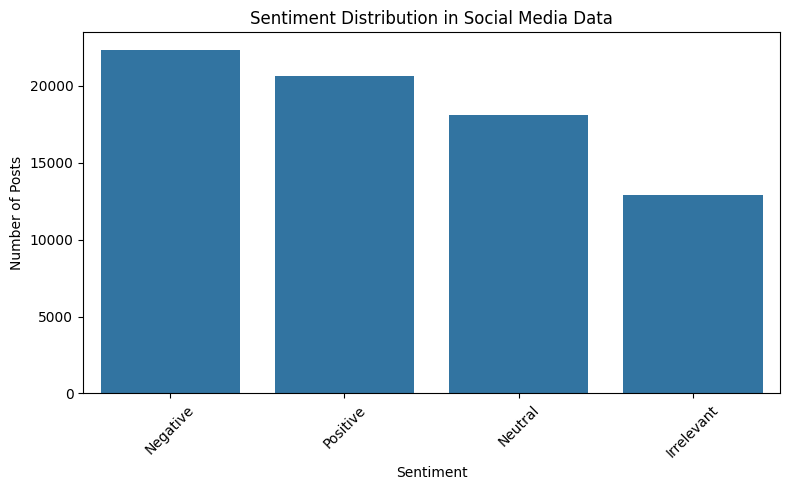

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Sentiment',
    order=df['Sentiment'].value_counts().index
)

plt.title('Sentiment Distribution in Social Media Data')
plt.xlabel('Sentiment')
plt.ylabel('Number of Posts')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

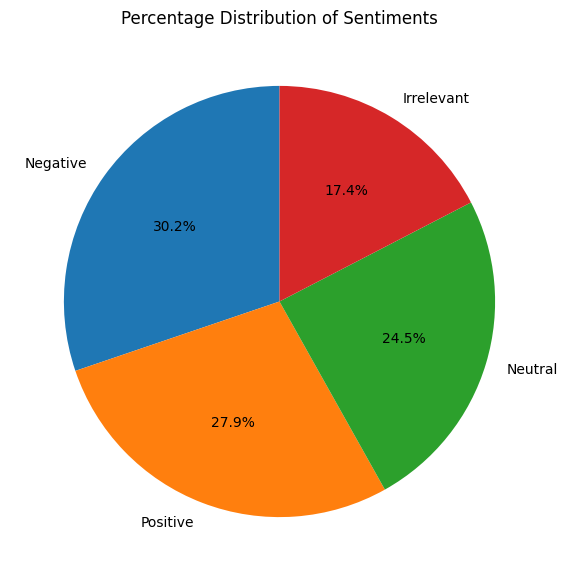

In [13]:
sentiment_counts = df['Sentiment'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage Distribution of Sentiments')
plt.show()

In [14]:
topic_sentiment = pd.crosstab(
    df['Topic'],
    df['Sentiment']
)

print(topic_sentiment.head(10))

Sentiment                  Irrelevant  Negative  Neutral  Positive
Topic                                                             
Amazon                            186       575     1207       308
ApexLegends                       192       591      936       634
AssassinsCreed                    264       375      156      1439
Battlefield                       915       464      351       586
Borderlands                       240       426      597      1017
CS-GO                             632       344      548       760
CallOfDuty                        672       883      375       446
CallOfDutyBlackopsColdWar         569       566      352       856
Cyberpunk2077                     465       385      462       950
Dota2                             425       767      588       579


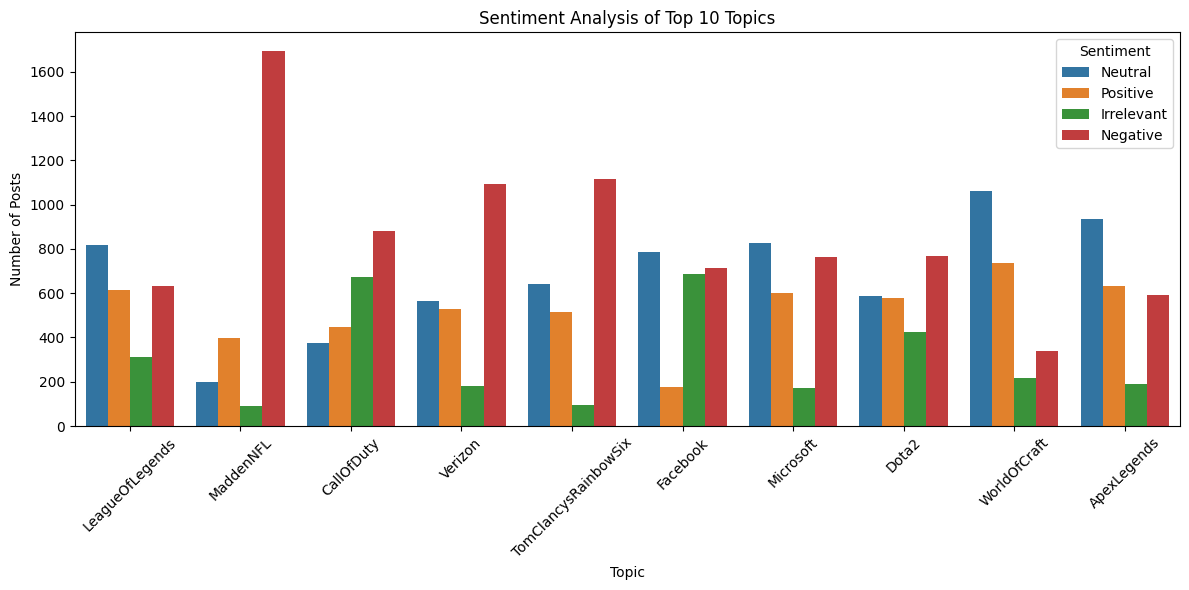

In [15]:
top_topics = df['Topic'].value_counts().head(10).index

topic_data = df[df['Topic'].isin(top_topics)]

plt.figure(figsize=(12, 6))

sns.countplot(
    data=topic_data,
    x='Topic',
    hue='Sentiment',
    order=top_topics
)

plt.title('Sentiment Analysis of Top 10 Topics')
plt.xlabel('Topic')
plt.ylabel('Number of Posts')
plt.xticks(rotation=45)
plt.legend(title='Sentiment')

plt.tight_layout()
plt.show()

In [17]:
print("SOCIAL MEDIA SENTIMENT ANALYSIS")
print("-" * 40)

print("\nTotal Posts:", len(df))

print("\nSentiment Counts:")
print(df['Sentiment'].value_counts())

print("\nMost Discussed Topics:")
print(df['Topic'].value_counts().head(5))

print("\nMost Common Sentiment:",
      df['Sentiment'].value_counts().idxmax())

SOCIAL MEDIA SENTIMENT ANALYSIS
----------------------------------------

Total Posts: 73996

Sentiment Counts:
Sentiment
Negative      22358
Positive      20655
Neutral       18108
Irrelevant    12875
Name: count, dtype: int64

Most Discussed Topics:
Topic
LeagueOfLegends         2377
MaddenNFL               2377
CallOfDuty              2376
Verizon                 2365
TomClancysRainbowSix    2364
Name: count, dtype: int64

Most Common Sentiment: Negative


### Conclusion

In this task, I analyzed social media data using Python. I created graphs to understand positive, negative, and neutral sentiments. This helped me learn how to analyze public opinions using data visualization.
